# Building Perceptron

**Classifying breast tumours with a single artificial neuron, written from scratch.**

La Plateforme — Rooney Nofal

---

## Introduction

This notebook builds a **Perceptron** — the first artificial neuron, invented by Frank
Rosenblatt in 1958 — entirely from scratch in NumPy, and applies it to a real medical
problem: telling a malignant breast tumour from a benign one.

No machine-learning library provides the model. `scikit-learn` is used only for the
supporting work (splitting, scaling, feature selection, metrics); the classifier itself
lives in `perceptron.py` and is roughly thirty lines of our own code.

The notebook runs in two parts:

| Part | What it does | Why |
| --- | --- | --- |
| **Part 1** | Tests the Perceptron on randomly generated data | Proves the implementation is correct before trusting it on real patients, and shows the one problem it cannot solve |
| **Part 2** | Applies it to the Breast Cancer Wisconsin dataset | Cleaning, exploration, dimensionality reduction, modelling and evaluation |

**The question we are answering:** given 30 measurements taken from a digitised image of
a breast-mass cell nucleus, can one flat decision boundary separate malignant from benign
— and how well?

## 0. Setup

Everything the notebook needs, imported once.

In [1]:
import numpy as np                                            # Fast arrays and all the numerical work.
import pandas as pd                                           # Tables: loading, cleaning and exploring the CSV.
import matplotlib.pyplot as plt                               # The plotting engine behind every figure here.
import seaborn as sns                                         # Statistical plots built on matplotlib.
from pathlib import Path                                      # Clean, portable file paths.
from matplotlib.ticker import MaxNLocator                     # Forces whole-number ticks where decimals make no sense.

from sklearn.model_selection import train_test_split          # Splits the data into a training and a test set.
from sklearn.preprocessing import StandardScaler              # Puts every feature on the same scale.
from sklearn.decomposition import PCA                         # Dimensionality reduction by principal components.
from sklearn.ensemble import RandomForestClassifier           # The forest Boruta uses to measure importance.
from sklearn.metrics import (confusion_matrix, accuracy_score, # Tools to score the model.
                             precision_score, recall_score,
                             f1_score, roc_curve, auc)
from boruta import BorutaPy                                   # All-relevant feature selection (Kursa & Rudnicki, 2010).

from perceptron import Perceptron                             # OUR model — the class we wrote in perceptron.py.

RANDOM_STATE = 42                                             # One seed for the whole notebook, so every run is identical.
FIGURES = Path("figures")                                     # Folder where the plots are saved for the slides.
FIGURES.mkdir(exist_ok=True)                                  # Create it if it is not already there.

sns.set_theme(style="whitegrid", palette="deep")              # A clean, consistent look for every chart.
plt.rcParams["figure.dpi"] = 110                              # Slightly sharper figures on screen.
plt.rcParams["savefig.dpi"] = 150                             # Higher resolution for the saved image files.

print("Setup complete.")                                      # Confirms the cell ran without an import error.

Setup complete.


---

# Part 1 — Testing the Perceptron on generated data

Before trusting the model with patient data, we check it on data we built ourselves,
where we already know the right answer. This is the step the brief asks for:
*"Tu le testes sur des données fictives générées aléatoirement."*

## 1.1 Two separable clouds

We generate 200 points in two dimensions: one cloud centred at (2, 2) labelled **1**, one
centred at (−2, −2) labelled **0**. Two dimensions so we can actually *see* the boundary
the Perceptron finds.

In [2]:
rng = np.random.RandomState(RANDOM_STATE)                     # A random generator fixed by our seed.

cloud_a = rng.randn(100, 2) + np.array([2, 2])                # 100 points scattered around the point (2, 2).
cloud_b = rng.randn(100, 2) + np.array([-2, -2])              # 100 points scattered around the point (-2, -2).

X_synth = np.vstack([cloud_a, cloud_b])                       # Stack both clouds into one array of 200 rows.
y_synth = np.hstack([np.ones(100, dtype=int),                 # Label the first cloud 1...
                     np.zeros(100, dtype=int)])               # ...and the second cloud 0.

print("Generated:", X_synth.shape[0], "points,", X_synth.shape[1], "features")  # Confirm the shape of what we made.
print("Class counts:", np.bincount(y_synth))                  # Confirm the two classes are balanced (100 / 100).

Generated: 200 points, 2 features
Class counts: [100 100]


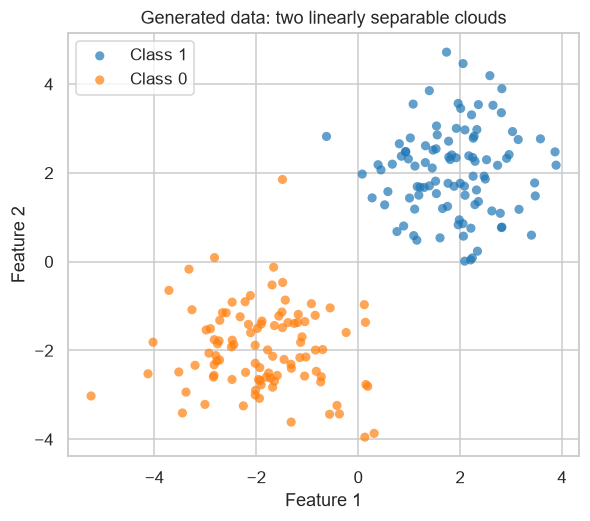

In [3]:
fig, ax = plt.subplots(figsize=(6, 5))                        # One figure with a single set of axes.
ax.scatter(cloud_a[:, 0], cloud_a[:, 1], c="tab:blue", label="Class 1", alpha=0.7, edgecolor="none")    # Class 1 in blue.
ax.scatter(cloud_b[:, 0], cloud_b[:, 1], c="tab:orange", label="Class 0", alpha=0.7, edgecolor="none")  # Class 0 in orange.
ax.set_xlabel("Feature 1")                                    # Name the horizontal axis.
ax.set_ylabel("Feature 2")                                    # Name the vertical axis.
ax.set_title("Generated data: two linearly separable clouds") # A title that states what the reader is looking at.
ax.legend()                                                   # Show which colour is which class.
fig.savefig(FIGURES / "01_synthetic_data.png", bbox_inches="tight")  # Save the figure for the slide deck.
plt.show()                                                    # Display it in the notebook.

The two groups are clearly apart, and a straight line could obviously be drawn between
them. This is exactly the situation the Perceptron was designed for — so if our
implementation cannot solve this, it is broken.

## 1.2 Training

We train for up to 50 epochs with a learning rate of 0.01, and record how many mistakes
the model makes in each pass.

In [4]:
p_synth = Perceptron(learning_rate=0.01, n_epochs=50, random_state=1)  # Create the model with its settings.
p_synth.fit(X_synth, y_synth)                                 # Train it on the generated data.

print("Errors per epoch :", p_synth.errors_)                  # The mistake count of each pass — our convergence curve.
print("Epochs used      :", len(p_synth.errors_))             # Fewer than 50 means it stopped early, having converged.
print("Accuracy         :", p_synth.score(X_synth, y_synth))  # Share of the 200 points classified correctly.
print("Learned weights  :", np.round(p_synth.weights_, 4))    # The two numbers that define the boundary's direction.
print("Learned bias     :", round(p_synth.bias_, 4))          # The number that shifts the boundary away from the origin.

Errors per epoch : [2, 1, 2, 0]
Epochs used      : 4
Accuracy         : 1.0
Learned weights  : [0.0411 0.0131]
Learned bias     : -0.01


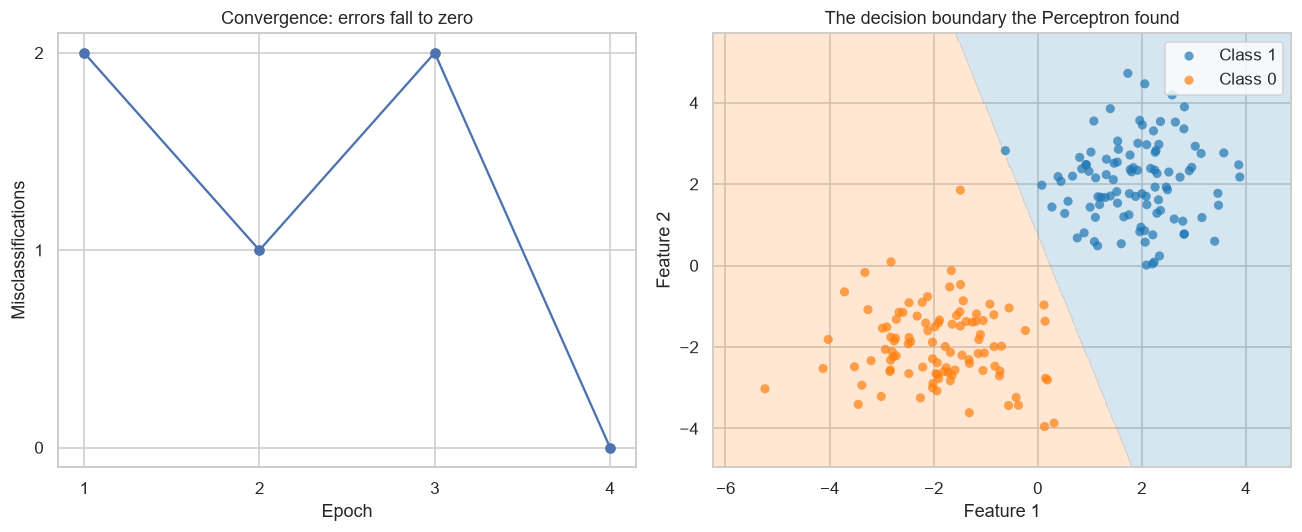

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))               # Two charts side by side in one figure.

axes[0].plot(range(1, len(p_synth.errors_) + 1),              # X axis: epoch number, starting at 1.
             p_synth.errors_, marker="o")                     # Y axis: mistakes in that epoch, with a dot per point.
axes[0].set_xlabel("Epoch")                                   # Name the horizontal axis.
axes[0].set_ylabel("Misclassifications")                      # Name the vertical axis.
axes[0].set_title("Convergence: errors fall to zero")         # State the finding in the title.
axes[0].xaxis.set_major_locator(MaxNLocator(integer=True))    # Epochs are whole numbers; no "1.5th epoch".
axes[0].yaxis.set_major_locator(MaxNLocator(integer=True))    # Mistakes are counted, so the ticks must be integers too.

x_min, x_max = X_synth[:, 0].min() - 1, X_synth[:, 0].max() + 1   # Horizontal range of the plotting grid.
y_min, y_max = X_synth[:, 1].min() - 1, X_synth[:, 1].max() + 1   # Vertical range of the plotting grid.
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),           # Build a dense grid of points covering the whole area...
                     np.arange(y_min, y_max, 0.02))           # ...so we can colour each region by its predicted class.
Z = p_synth.predict(np.c_[xx.ravel(), yy.ravel()])            # Ask the model to classify every point on that grid.
Z = Z.reshape(xx.shape)                                       # Fold the answers back into the grid's shape.

axes[1].contourf(xx, yy, Z, alpha=0.18, levels=1,             # Shade the two regions the model separates...
                 colors=["tab:orange", "tab:blue"])           # ...in the SAME colours as the dots: orange = 0, blue = 1.
axes[1].scatter(cloud_a[:, 0], cloud_a[:, 1], c="tab:blue", label="Class 1", alpha=0.7, edgecolor="none")    # Class 1 points.
axes[1].scatter(cloud_b[:, 0], cloud_b[:, 1], c="tab:orange", label="Class 0", alpha=0.7, edgecolor="none")  # Class 0 points.
axes[1].set_xlabel("Feature 1")                               # Name the horizontal axis.
axes[1].set_ylabel("Feature 2")                               # Name the vertical axis.
axes[1].set_title("The decision boundary the Perceptron found")  # State what the shading means.
axes[1].legend()                                              # Show which colour is which class.

fig.tight_layout()                                            # Stop the two charts overlapping.
fig.savefig(FIGURES / "02_synthetic_result.png", bbox_inches="tight")  # Save for the slides.
plt.show()                                                    # Display it.

**Reading the figures.** On the left the error count drops to zero and training stops
early — the model stopped because it had nothing left to correct, not because it ran out
of epochs. On the right, the boundary is a straight line sitting cleanly between the two
clouds.

This confirms two things at once: our implementation is correct, and it behaves exactly as
Novikoff's 1962 convergence theorem predicts — *on linearly separable data the Perceptron
rule reaches a solution in a finite number of steps.*

## 1.3 The limitation: AND works, XOR does not

The same theorem has a second half: if the classes **cannot** be separated by a straight
line, training never settles. The classic demonstration uses two logical functions on the
same four points.

| x₁ | x₂ | AND | XOR |
| --- | --- | --- | --- |
| 0 | 0 | 0 | 0 |
| 0 | 1 | 0 | 1 |
| 1 | 0 | 0 | 1 |
| 1 | 1 | 1 | 0 |

For **AND**, the single 1 sits in one corner and a line separates it easily. For **XOR**,
the two 1s sit at opposite corners and the two 0s at the other opposite corners — the
classes are interleaved diagonally, and **no straight line exists**.

In [6]:
X_logic = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])          # The four input combinations, shared by both functions.
y_and = np.array([0, 0, 0, 1])                                # AND: true only when both inputs are 1.
y_xor = np.array([0, 1, 1, 0])                                # XOR: true only when the inputs differ.

p_and = Perceptron(learning_rate=0.1, n_epochs=20, random_state=1).fit(X_logic, y_and)  # Train on AND.
p_xor = Perceptron(learning_rate=0.1, n_epochs=20, random_state=1).fit(X_logic, y_xor)  # Train on XOR.

print("AND -> errors per epoch:", p_and.errors_)              # Should reach zero and stop.
print("AND -> accuracy        :", p_and.score(X_logic, y_and))# Should be 1.0, a perfect score.
print()                                                       # A blank line, to separate the two results.
print("XOR -> errors per epoch:", p_xor.errors_)              # Should never reach zero, however long it runs.
print("XOR -> accuracy        :", p_xor.score(X_logic, y_xor))# Will stay poor, whatever we do.

AND -> errors per epoch: [2, 3, 1, 0]
AND -> accuracy        : 1.0

XOR -> errors per epoch: [3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
XOR -> accuracy        : 0.25


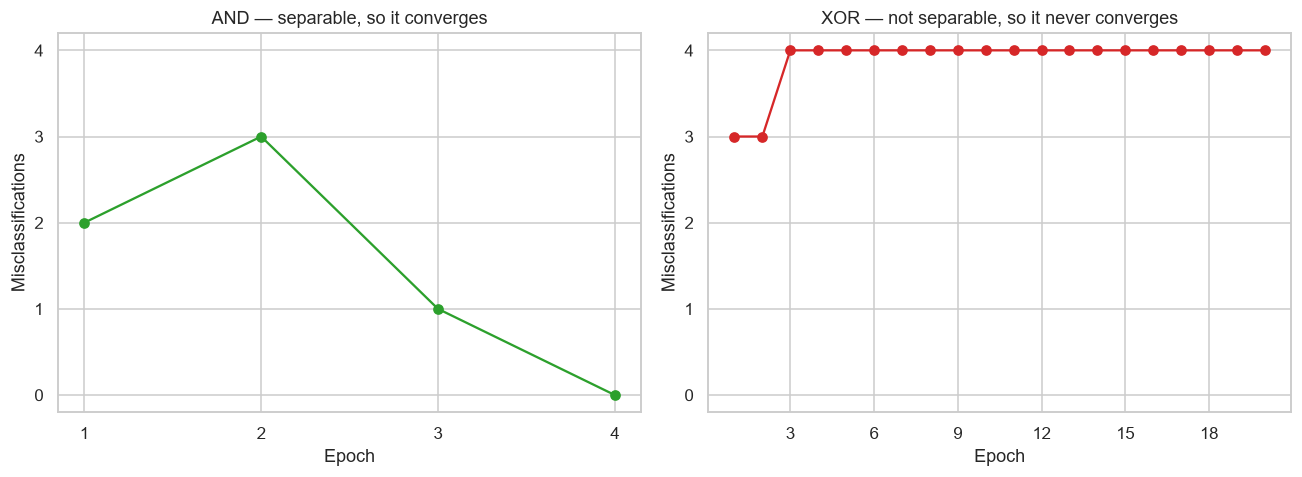

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))             # Two charts side by side.

axes[0].plot(range(1, len(p_and.errors_) + 1), p_and.errors_, marker="o", color="tab:green")  # AND's error curve.
axes[0].set_title("AND — separable, so it converges")         # State the outcome in the title.
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Misclassifications")  # Name both axes.
axes[0].set_ylim(-0.2, 4.2)                                   # Same vertical range on both charts, so they compare fairly.
axes[0].xaxis.set_major_locator(MaxNLocator(integer=True))    # Epochs are whole numbers.
axes[0].yaxis.set_major_locator(MaxNLocator(integer=True))    # So are counts of mistakes.

axes[1].plot(range(1, len(p_xor.errors_) + 1), p_xor.errors_, marker="o", color="tab:red")    # XOR's error curve.
axes[1].set_title("XOR — not separable, so it never converges")  # State the outcome in the title.
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Misclassifications")  # Name both axes.
axes[1].set_ylim(-0.2, 4.2)                                   # Matching range, as above.
axes[1].xaxis.set_major_locator(MaxNLocator(integer=True))    # Epochs are whole numbers.
axes[1].yaxis.set_major_locator(MaxNLocator(integer=True))    # So are counts of mistakes.

fig.tight_layout()                                            # Keep the two charts from colliding.
fig.savefig(FIGURES / "03_and_vs_xor.png", bbox_inches="tight")  # Save for the slides.
plt.show()                                                    # Display it.

**Reading the figures.** AND's error count falls to zero within a few epochs and training
stops. XOR's never does — it flattens out at a non-zero value and would stay there if we
ran it for a million epochs. The algorithm has no way of noticing that no solution exists.

This is the Perceptron's defining limitation, and the reason Minsky and Papert's 1969 book
*Perceptrons* is remembered. The fix arrived in 1986 with backpropagation: a network with
one hidden layer solves XOR without difficulty.

**Why this matters for Part 2:** real medical data is rarely perfectly separable either.
We should therefore expect the error count on the patient data to fall quickly and then
oscillate rather than reach zero — and that will be the algorithm working correctly, not
a bug in our code.

---

# Part 2 — Breast Cancer Wisconsin

## 2.1 Loading the data

The dataset contains 569 breast masses. For each one, a digitised image of a fine needle
aspirate was analysed and **ten properties of the cell nuclei** were measured: radius,
texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry and
fractal dimension.

Each of those ten is reported three ways — the **mean**, the **standard error** (`_se`),
and the **worst** (largest) value found in the image — giving 30 numeric features per
patient. The target is the diagnosis: **M** for malignant, **B** for benign.

In [8]:
df = pd.read_csv("data/bcw_data.csv")                         # Read the raw CSV into a pandas table.

print("Shape:", df.shape)                                     # How many rows and columns we actually got.
print()                                                       # Blank line for readability.
df.head()                                                     # Show the first five rows, to see what we are working with.

Shape: (569, 33)



,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [9]:
df.info()                                                     # Column names, how many non-empty values each has, and its type.

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

Two problems are already visible, and both need fixing before anything else.

## 2.2 Cleaning

1. **`Unnamed: 32`** — a column with 0 non-null values out of 569. The raw file's header
   line ends with a stray comma, which makes pandas invent an entirely empty column.
2. **`id`** — a patient identifier. It is a number, so a model would happily use it, but
   it carries no medical meaning whatsoever. Feeding it to the Perceptron would be letting
   the model learn from an accident of how the records were numbered.
3. **`diagnosis`** — text (`M` / `B`). Our model does arithmetic, so it needs numbers.

We encode **malignant as 1** and **benign as 0**. That choice is deliberate: in medical
testing the condition being screened for is the *positive* class, so "recall" will mean
"the share of real cancers we caught" — the number that matters most here.

In [10]:
print("Missing values per column (only those with any):")     # Announce what the next line prints.
print(df.isna().sum()[df.isna().sum() > 0])                   # List only the columns that actually have missing values.
print()                                                       # Blank line.
print("Duplicate rows:", df.duplicated().sum())               # Check no patient was recorded twice.

Missing values per column (only those with any):
Unnamed: 32    569
dtype: int64

Duplicate rows: 0


In [11]:
data = df.drop(columns=["id", "Unnamed: 32"])                 # Remove the identifier and the empty phantom column.
data["diagnosis"] = data["diagnosis"].map({"M": 1, "B": 0})   # Turn the text diagnosis into 1 (malignant) / 0 (benign).

X = data.drop(columns="diagnosis")                            # X holds the 30 measurements — the model's inputs.
y = data["diagnosis"]                                         # y holds the answer we want the model to learn.

print("Features :", X.shape[1], "columns,", X.shape[0], "rows")   # Confirm we kept 30 features and all 569 patients.
print("Missing  :", int(X.isna().sum().sum()))                # Confirm nothing is missing after cleaning.
print("Target   :", dict(y.value_counts()))                   # Confirm the encoding worked: counts for 1 and 0.

Features : 30 columns, 569 rows
Missing  : 0
Target   : {0: np.int64(357), 1: np.int64(212)}


Clean: 569 patients, 30 features, no missing values, no duplicates, target encoded.

## 2.3 Exploratory analysis

### Class balance

The first thing to check in any classification problem: how many of each class?

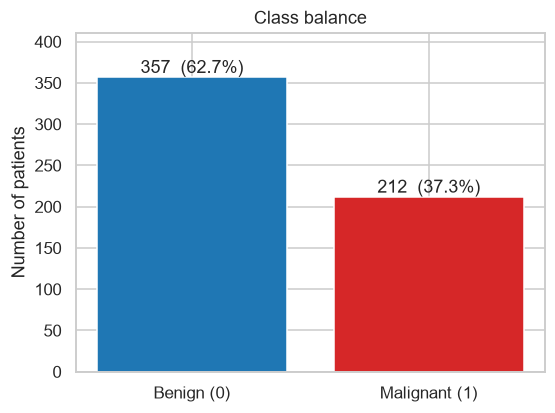

In [12]:
counts = y.value_counts().sort_index()                        # Count each class, ordered 0 then 1.
labels = ["Benign (0)", "Malignant (1)"]                      # Readable names for the two classes.

fig, ax = plt.subplots(figsize=(5.5, 4))                      # One modest-sized chart.
bars = ax.bar(labels, counts.values, color=["tab:blue", "tab:red"])  # Blue for benign, red for malignant.
for bar, value in zip(bars, counts.values):                   # Walk through the bars and their numbers together.
    ax.text(bar.get_x() + bar.get_width() / 2, value + 5,     # Position a label just above each bar...
            f"{value}  ({value / len(y):.1%})",               # ...showing the count and the percentage.
            ha="center")                                      # Centre the text on the bar.
ax.set_ylabel("Number of patients")                           # Name the vertical axis.
ax.set_title("Class balance")                                 # Title the chart.
ax.set_ylim(0, max(counts.values) * 1.15)                     # Leave headroom so the labels are not clipped.
fig.savefig(FIGURES / "04_class_balance.png", bbox_inches="tight")  # Save for the slides.
plt.show()                                                    # Display it.

**Interpretation.** 357 benign against 212 malignant — roughly 63% / 37%. Not a severe
imbalance, but real enough to matter in two ways:

- **Accuracy will flatter the model.** Answering "benign" to every single patient scores
  63% without learning anything. Any accuracy we report has to be judged against that
  floor.
- **The split must be stratified**, so the training and test sets keep the same proportion
  of each class.

### Descriptive statistics

In [13]:
X.describe().T[["mean", "std", "min", "max"]].round(3)        # Summary of every feature: centre, spread and range.

,mean,std,min,max
radius_mean,14.127,3.524,6.981,28.110
texture_mean,19.290,4.301,9.710,39.280
perimeter_mean,91.969,24.299,43.790,188.500
area_mean,654.889,351.914,143.500,2501.000
smoothness_mean,0.096,0.014,0.053,0.163
compactness_mean,0.104,0.053,0.019,0.345
concavity_mean,0.089,0.080,0.000,0.427
concave points_mean,0.049,0.039,0.000,0.201
symmetry_mean,0.181,0.027,0.106,0.304
fractal_dimension_mean,0.063,0.007,0.050,0.097


**Interpretation — and the single most important observation in this notebook.** Look at
the `max` column. `area_worst` reaches roughly 4250, while `fractal_dimension_se` stays
around 0.03. **That is a ratio of more than a hundred thousand to one.**

This breaks the Perceptron if left untreated. The learning rule adds `η · error · xᵢ` to
each weight, so the size of every correction is proportional to the feature's own value.
Features measured in thousands would produce corrections a hundred thousand times larger
than features measured in hundredths, and would dominate the model completely — not
because they matter more medically, but because of the units they happen to be recorded
in.

We fix this with standardisation in section 2.4.

### How the features separate the two classes

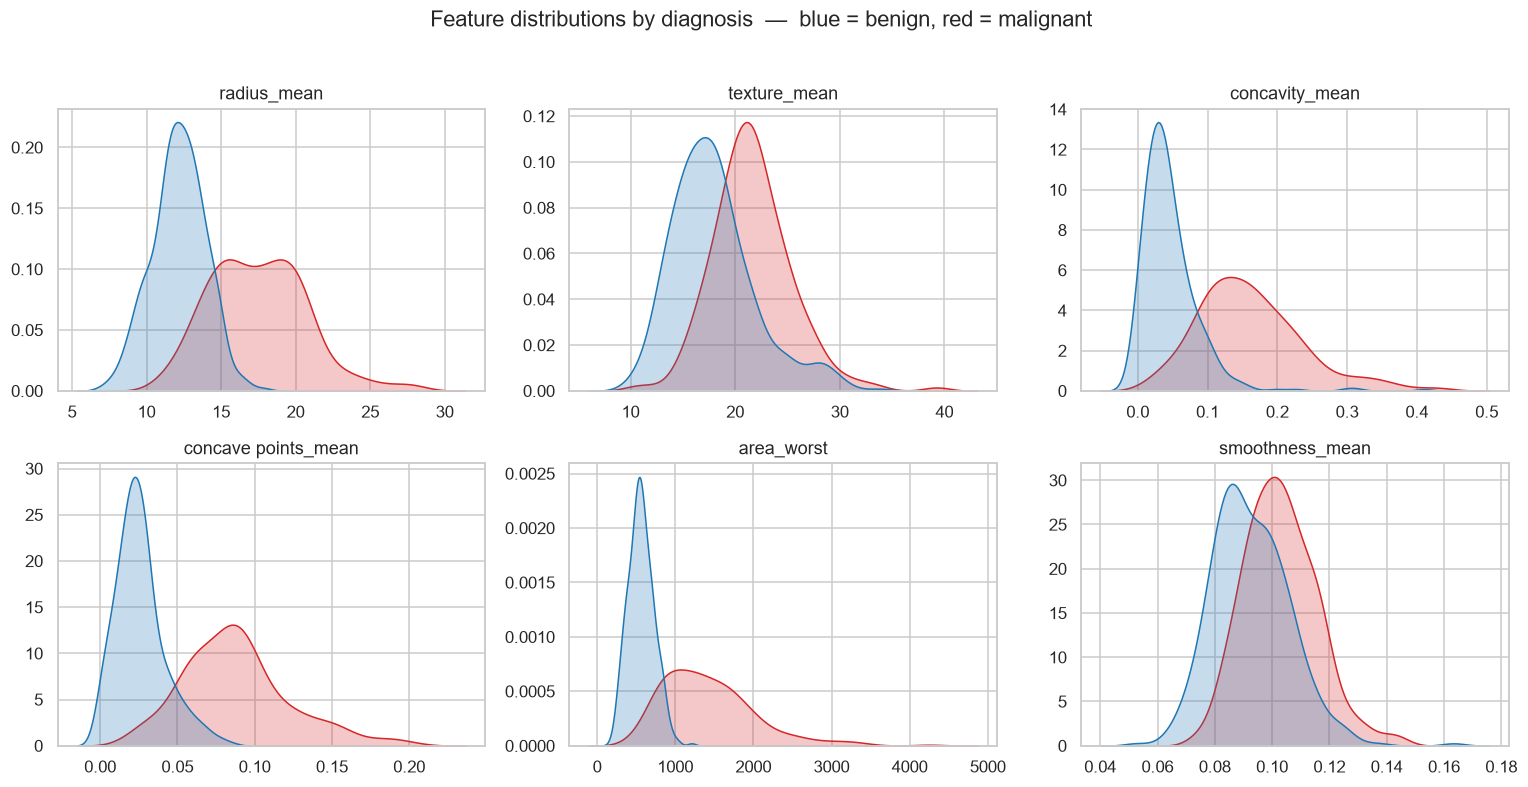

In [14]:
key_features = ["radius_mean", "texture_mean", "concavity_mean",   # Six features chosen to show a range of behaviours:
                "concave points_mean", "area_worst", "smoothness_mean"]  # some separate the classes well, some barely.

fig, axes = plt.subplots(2, 3, figsize=(14, 7))               # A grid of 2 rows by 3 columns of charts.
for ax, feature in zip(axes.ravel(), key_features):           # Pair each chart with one feature.
    sns.kdeplot(data=data, x=feature, hue="diagnosis",        # Draw a smooth distribution curve per class.
                fill=True, common_norm=False, ax=ax,          # Fill under the curves; scale each class separately.
                palette={0: "tab:blue", 1: "tab:red"}, legend=False)  # Blue benign, red malignant.
    ax.set_title(feature)                                     # Name the feature above its chart.
    ax.set_xlabel("")                                         # The title already names it; printing it twice is clutter.
    ax.set_ylabel("")                                         # Drop the repeated y label; it adds nothing here.

fig.suptitle("Feature distributions by diagnosis  —  blue = benign, red = malignant", y=1.02)  # One shared title.
fig.tight_layout()                                            # Keep the six charts from overlapping.
fig.savefig(FIGURES / "05_distributions.png", bbox_inches="tight")  # Save for the slides.
plt.show()                                                    # Display it.

**Interpretation.** `concave points_mean`, `radius_mean` and `area_worst` show two clearly
displaced humps — malignant tumours are larger and have more concave contour points. These
features carry real signal.

`smoothness_mean` and `texture_mean` overlap far more heavily: on their own they would
separate almost nothing. This is a preview of what feature selection will tell us formally
in section 2.5.

### Correlation between features

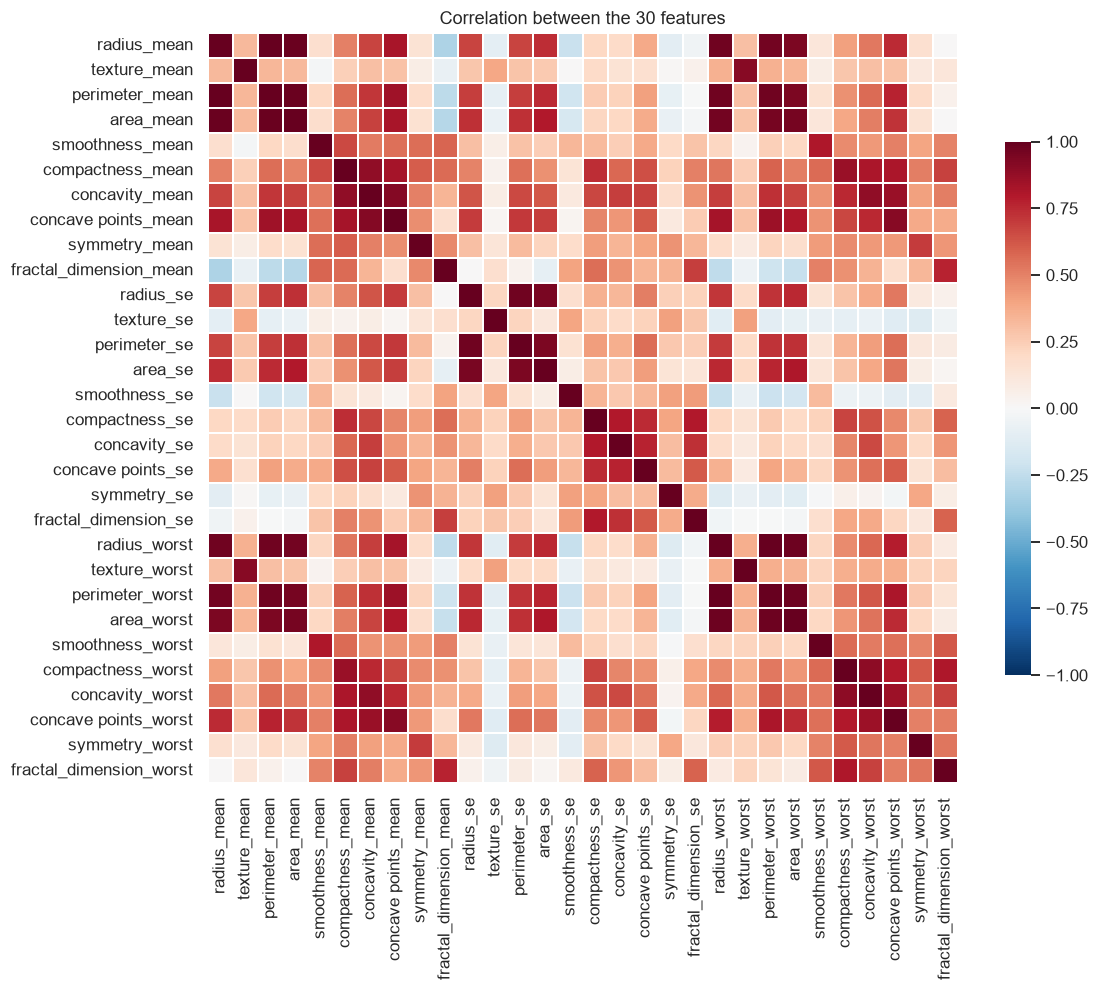

Pairs of features correlated above 0.9: 21
  area_mean                    <-> area_worst                    r = 0.959
  area_mean                    <-> perimeter_mean                r = 0.987
  area_mean                    <-> perimeter_worst               r = 0.959
  area_mean                    <-> radius_mean                   r = 0.987
  area_mean                    <-> radius_worst                  r = 0.963
  area_se                      <-> perimeter_se                  r = 0.938
  area_se                      <-> radius_se                     r = 0.952
  area_worst                   <-> perimeter_mean                r = 0.942


In [15]:
corr = X.corr()                                               # Correlation of every feature with every other feature.

fig, ax = plt.subplots(figsize=(11, 9))                       # A large figure — there are 30 x 30 cells to show.
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1,   # Red for positive, blue for negative, white at zero.
            square=True, linewidths=0.2, cbar_kws={"shrink": 0.7}, ax=ax)  # Square cells, thin gridlines, smaller colour bar.
ax.set_title("Correlation between the 30 features")           # Title the chart.
fig.savefig(FIGURES / "06_correlation.png", bbox_inches="tight")  # Save for the slides.
plt.show()                                                    # Display it.

high = (corr.abs() > 0.9) & (corr.abs() < 1.0)                # Find pairs that are almost the same measurement.
pairs = {tuple(sorted((a, b))) for a in corr.columns          # Collect each such pair once, in a consistent order...
         for b in corr.columns if high.loc[a, b]}             # ...so (a, b) and (b, a) are not both listed.
print(f"Pairs of features correlated above 0.9: {len(pairs)}")# How much redundancy there is in total.
for a, b in sorted(pairs)[:8]:                                # Show the first eight as examples.
    print(f"  {a:28s} <-> {b:28s}  r = {corr.loc[a, b]:.3f}") # Print the pair and its correlation.

**Interpretation.** The heatmap is dominated by deep red blocks, and the count confirms
why: many pairs of features are correlated above 0.9.

This is not an accident in the data — it is geometry. `radius`, `perimeter` and `area` are
three ways of measuring the same circle: if you know the radius you can compute the other
two. The same relationship repeats across the `_mean`, `_se` and `_worst` versions of every
measurement.

Heavy redundancy has a direct consequence for section 2.5: **Boruta will keep almost
everything**, because every one of those correlated features genuinely carries information
about the diagnosis. That is Boruta behaving exactly as designed, and it is why we will
chain a correlation filter after it.

## 2.4 Preprocessing

Two steps, and the order matters enormously.

**Split first, then scale.** The scaler learns a mean and a standard deviation from the
data it is fitted on. If we fit it on all 569 patients and *then* split, information from
the test set has already leaked into the training process, and every score we report
afterwards is optimistic — quietly, invisibly, and wrongly. Fitting the scaler on the
training set alone and merely *applying* it to the test set keeps the test set genuinely
unseen.

The split is **stratified**, so both sets keep the 63/37 class proportion we measured.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(          # Split the data into a training and a test set.
    X, y,                                                     # The features and the labels to split together.
    test_size=0.2,                                            # Keep 20% of patients aside, untouched, for testing.
    stratify=y,                                               # Preserve the 63/37 class balance in both sets.
    random_state=RANDOM_STATE)                                # Fix the randomness so the split never changes.

scaler = StandardScaler()                                     # The tool that rescales each feature to mean 0, std 1.
X_train_s = scaler.fit_transform(X_train)                     # LEARN the mean and spread from the training set, and apply.
X_test_s = scaler.transform(X_test)                           # APPLY the training set's numbers to the test set — never relearn.

y_train_a = y_train.to_numpy()                                # Labels as a plain NumPy array, which our Perceptron expects.
y_test_a = y_test.to_numpy()                                  # Same for the test labels.

print(f"Training set : {X_train_s.shape[0]} patients  ({y_train.mean():.1%} malignant)")  # Size and balance of the training set.
print(f"Test set     : {X_test_s.shape[0]} patients  ({y_test.mean():.1%} malignant)")    # Size and balance of the test set.
print(f"After scaling, mean = {X_train_s.mean():.2e}, std = {X_train_s.std():.3f}")       # Proof the scaling worked: ~0 and ~1.

Training set : 455 patients  (37.4% malignant)
Test set     : 114 patients  (36.8% malignant)
After scaling, mean = 1.60e-17, std = 1.000


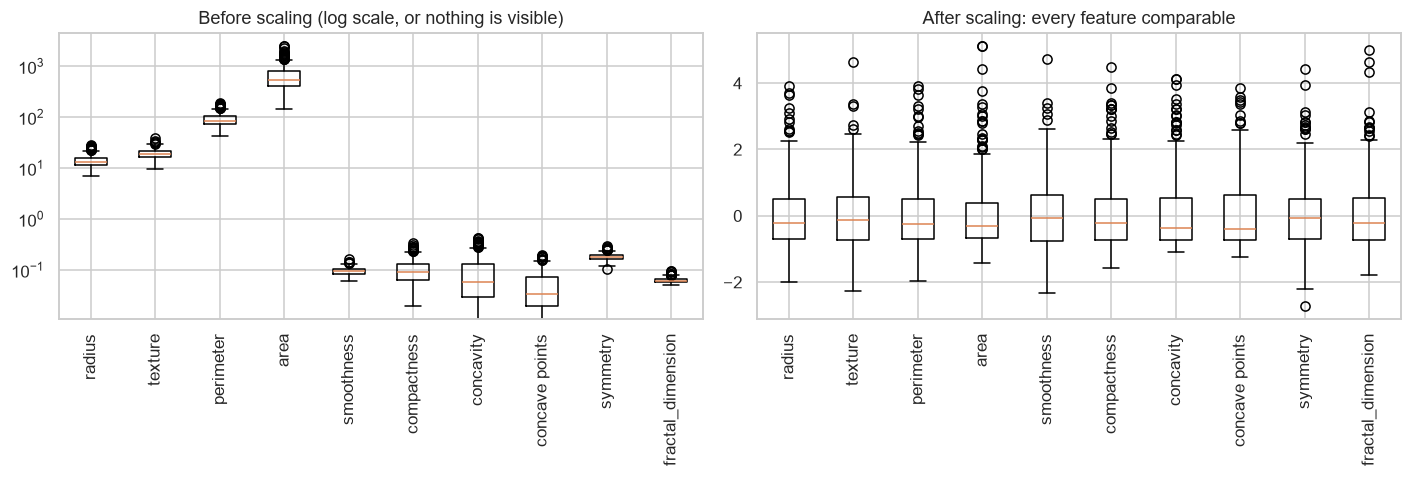

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))             # Two charts: before scaling and after.
names = [c.replace("_mean", "") for c in X_train.columns[:10]]# Drop the shared "_mean" suffix: complete names, not truncated.

axes[0].boxplot([X_train.iloc[:, i] for i in range(10)],      # Box plot of the first ten features, raw.
                tick_labels=names)                            # Full, readable feature names.
axes[0].set_yscale("log")                                     # Log scale — otherwise the small features are invisible.
axes[0].set_title("Before scaling (log scale, or nothing is visible)")  # Say why the axis is logarithmic.
axes[0].tick_params(axis="x", rotation=90)                    # Turn the labels so they do not overlap.

axes[1].boxplot([X_train_s[:, i] for i in range(10)],         # The same ten features after standardisation.
                tick_labels=names)                            # The same full names.
axes[1].set_title("After scaling: every feature comparable")  # State the result.
axes[1].tick_params(axis="x", rotation=90)                    # Turn the labels again.

fig.tight_layout()                                            # Prevent the rotated labels being cut off.
fig.savefig(FIGURES / "07_scaling.png", bbox_inches="tight")  # Save for the slides.
plt.show()                                                    # Display it.

**Interpretation.** The left panel needs a *logarithmic* axis for the small features to be
visible at all next to the large ones — which is the problem stated visually. On the right,
after standardisation, every feature occupies a comparable range and no single measurement
can dominate the learning purely because of its units.

## 2.5 Dimensionality reduction

The brief asks us to reduce the dimensionality by a method of our choice. We use the method
from the course material — **Boruta** — and then do something the course material itself
recommends.

### How Boruta works

Boruta answers one question per feature: *does this feature carry more information than
pure noise?* It does so by competing each feature against a fake version of itself:

1. **Shadow features.** Every column is duplicated and the copy's values are shuffled
   randomly between rows. The copy keeps the same distribution but loses all connection to
   the diagnosis — it is noise built to look exactly as tempting as the original.
2. **A Random Forest** is trained on the doubled table and the importance of every column
   is measured.
3. **A hit** is scored when a real feature beats the best shadow of that round (the MZSA —
   *Max Z-Score Among Shadow Attributes*).
4. **A statistical test.** A useless feature should beat the best shadow about half the
   time, like a coin flip, so hit counts follow a binomial distribution B(N, 0.5).
   Features with significantly more hits are **Confirmed**, significantly fewer are
   **Rejected**, the undecided stay **Tentative**.

Crucially, Boruta is an **all-relevant** method: it keeps every feature that beats noise,
*including redundant ones*. Given what the correlation heatmap showed, we should expect it
to discard very little.

In [18]:
forest = RandomForestClassifier(n_jobs=-1,                    # Use every processor core; Boruta trains many forests.
                                max_depth=5,                  # Shallow trees: less overfitting of noise, and faster.
                                class_weight="balanced",      # Reweight the classes so the rarer one is not ignored.
                                random_state=RANDOM_STATE)    # Fix the randomness for reproducibility.

boruta = BorutaPy(forest,                                     # The selector, built around that forest.
                  n_estimators="auto",                        # Let Boruta choose the number of trees itself.
                  max_iter=60,                                # Up to 60 rounds of shadow-versus-real competition.
                  random_state=RANDOM_STATE,                  # Fix the randomness here too.
                  verbose=0)                                  # Keep the output quiet.

boruta.fit(X_train_s, y_train_a)                              # Run it on the TRAINING set only — never the test set.

confirmed = X.columns[boruta.support_].tolist()               # Features Boruta judged clearly better than noise.
tentative = X.columns[boruta.support_weak_].tolist()          # Features it could not decide about within 60 rounds.
rejected = [c for c in X.columns                              # Everything else was rejected as no better than noise.
            if c not in confirmed and c not in tentative]

print(f"Confirmed : {len(confirmed):2d} of 30")               # How many survived.
print(f"Tentative : {len(tentative):2d} of 30")               # How many are undecided.
print(f"Rejected  : {len(rejected):2d} of 30")                # How many were discarded.
print()                                                       # Blank line.
print("Rejected features:", rejected if rejected else "none") # Name the discarded ones — usually the weak overlapping ones.

c:\Users\User\Desktop\building-perceptron\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\User\Desktop\building-perceptron\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\User\Desktop\building-perceptron\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\User\Desktop\building-

Confirmed : 24 of 30
Tentative :  2 of 30
Rejected  :  4 of 30

Rejected features: ['fractal_dimension_mean', 'texture_se', 'smoothness_se', 'symmetry_se']


**Interpretation.** Boruta discards very little — exactly as the correlation heatmap
predicted and exactly as your course material warns:

> *"Garde les variables redondantes ou corrélées : réduit peu la dimension."*

This is not Boruta failing. It is Boruta succeeding at the job it was designed for. Its
goal is **all-relevant** selection — find everything that carries signal — not
**minimal-optimal** selection, which finds the smallest sufficient subset. `perimeter_mean`
really does carry information about malignancy, even though `radius_mean` already tells us
almost the same thing.

### Chaining a correlation filter

The course material names the remedy in the same breath:

> *"Pour un modèle compact, on peut enchaîner avec un filtrage des variables trop
> corrélées."*

So we take Boruta's confirmed list and, for every pair correlated above 0.9, keep only one.

In [19]:
corr_conf = X_train[confirmed].corr().abs()                   # Correlations among the confirmed features only.
to_drop = set()                                               # Will hold the features we decide to remove.

for i, a in enumerate(confirmed):                             # Walk through each confirmed feature...
    for b in confirmed[i + 1:]:                               # ...and compare it with every later one (each pair once).
        if a not in to_drop and corr_conf.loc[a, b] > 0.9:    # If they are near-duplicates and we are keeping 'a'...
            to_drop.add(b)                                    # ...then drop 'b' as redundant.

filtered = [c for c in confirmed if c not in to_drop]         # The compact list: confirmed, minus the redundant ones.

print(f"Boruta confirmed      : {len(confirmed)} features")   # Before the filter.
print(f"Dropped as redundant  : {len(to_drop)} features")     # How many near-duplicates we removed.
print(f"Remaining             : {len(filtered)} features")    # After the filter — our compact set.
print()                                                       # Blank line.
print("Kept:", filtered)                                      # Name the survivors, for the report.

Boruta confirmed      : 24 features
Dropped as redundant  : 9 features
Remaining             : 15 features

Kept: ['radius_mean', 'texture_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'radius_se', 'compactness_se', 'concavity_se', 'concave points_se', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']


### PCA, as a third approach

Boruta and the correlation filter both **select** original columns, so the result stays
interpretable — each kept feature is still a real measurement a doctor can name. PCA does
something different: it **builds new features**, each a mixture of all thirty originals,
ordered so the first captures the most variance.

That buys compactness at the cost of meaning: "principal component 1" is not a quantity
anyone can measure with a microscope. We include it because it gives us a fair third
comparison — and because its first two components let us draw the decision boundary in
section 2.7.

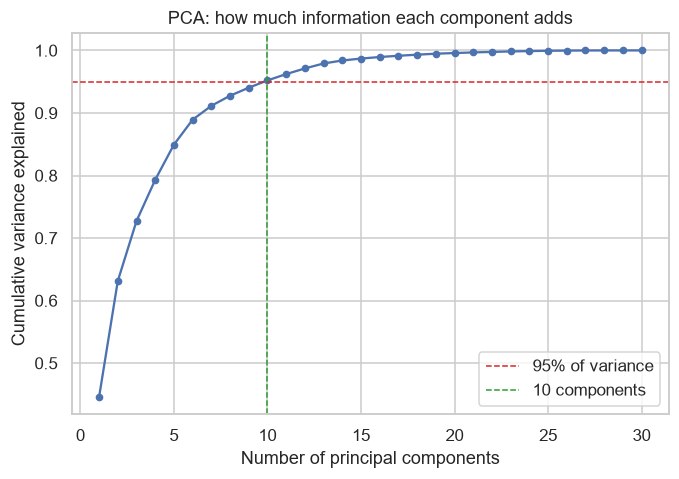

10 components explain 95% of the variance of 30 original features.
First two components alone explain 63.1%.


In [20]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_train_s)      # Fit PCA on the scaled TRAINING set only.
cumulative = np.cumsum(pca_full.explained_variance_ratio_)    # Running total of variance explained as we add components.
n_95 = int(np.argmax(cumulative >= 0.95) + 1)                 # How many components it takes to reach 95% of the variance.

fig, ax = plt.subplots(figsize=(7, 4.5))                      # One chart.
ax.plot(range(1, 31), cumulative, marker="o", ms=4)           # The cumulative curve, one dot per component.
ax.axhline(0.95, color="tab:red", ls="--", lw=1, label="95% of variance")  # A reference line at 95%.
ax.axvline(n_95, color="tab:green", ls="--", lw=1, label=f"{n_95} components")  # Where the curve crosses it.
ax.set_xlabel("Number of principal components")               # Name the horizontal axis.
ax.set_ylabel("Cumulative variance explained")                # Name the vertical axis.
ax.set_title("PCA: how much information each component adds") # Title the chart.
ax.legend()                                                   # Show what the two dashed lines mean.
fig.savefig(FIGURES / "08_pca_variance.png", bbox_inches="tight")  # Save for the slides.
plt.show()                                                    # Display it.

print(f"{n_95} components explain 95% of the variance of 30 original features.")  # The headline number.
print(f"First two components alone explain {cumulative[1]:.1%}.")                 # Useful for the 2D plot later.

In [21]:
pca = PCA(n_components=n_95, random_state=RANDOM_STATE)       # Keep just enough components for 95% of the variance.
X_train_pca = pca.fit_transform(X_train_s)                    # LEARN the components from the training set, and apply.
X_test_pca = pca.transform(X_test_s)                          # APPLY the same transformation to the test set.

idx_conf = [X.columns.get_loc(c) for c in confirmed]          # Column positions of the Boruta-confirmed features.
idx_filt = [X.columns.get_loc(c) for c in filtered]           # Column positions of the compact filtered set.

feature_sets = {                                              # The four candidate inputs we will compare.
    "All 30 features":            (X_train_s, X_test_s),                          # The untouched baseline.
    f"Boruta ({len(confirmed)})": (X_train_s[:, idx_conf], X_test_s[:, idx_conf]),# Everything that beats noise.
    f"Boruta + filter ({len(filtered)})": (X_train_s[:, idx_filt], X_test_s[:, idx_filt]),  # The compact selection.
    f"PCA ({n_95} comps)":        (X_train_pca, X_test_pca),                      # Built features, not selected ones.
}

for name, (tr, te) in feature_sets.items():                   # Walk through the four sets...
    print(f"{name:28s} train {tr.shape}   test {te.shape}")   # ...and confirm the shape of each.

All 30 features              train (455, 30)   test (114, 30)
Boruta (24)                  train (455, 24)   test (114, 24)
Boruta + filter (15)         train (455, 15)   test (114, 15)
PCA (10 comps)               train (455, 10)   test (114, 10)


## 2.6 Modelling with our Perceptron

We now train the class from `perceptron.py` on each of the four feature sets and compare.

A word on the settings: a learning rate of 0.01 and 100 epochs. We established in section
2.3 of the theory that the learning rate barely matters when weights start near zero — and
ours start at random values of about 0.01, so it has only a mild effect. 100 epochs is
generous: separable data would stop far earlier, and non-separable data will use all of
them.

In [22]:
model = Perceptron(learning_rate=0.01, n_epochs=100, random_state=1)  # The same model, now on real patient data.
model.fit(X_train_s, y_train_a)                               # Train on all 30 standardised features.

print(f"Epochs used        : {len(model.errors_)} of 100")    # If it used all 100, it never converged.
print(f"Errors, first five : {model.errors_[:5]}")            # How fast the big mistakes disappear.
print(f"Errors, last five  : {model.errors_[-5:]}")           # Where it ends up — zero, or oscillating?
print(f"Training accuracy  : {model.score(X_train_s, y_train_a):.4f}")  # How well it fits the data it saw.
print(f"Test accuracy      : {model.score(X_test_s, y_test_a):.4f}")    # How well it generalises to unseen patients.

Epochs used        : 100 of 100
Errors, first five : [34, 18, 17, 17, 13]
Errors, last five  : [9, 11, 6, 13, 7]
Training accuracy  : 0.9912
Test accuracy      : 0.9386


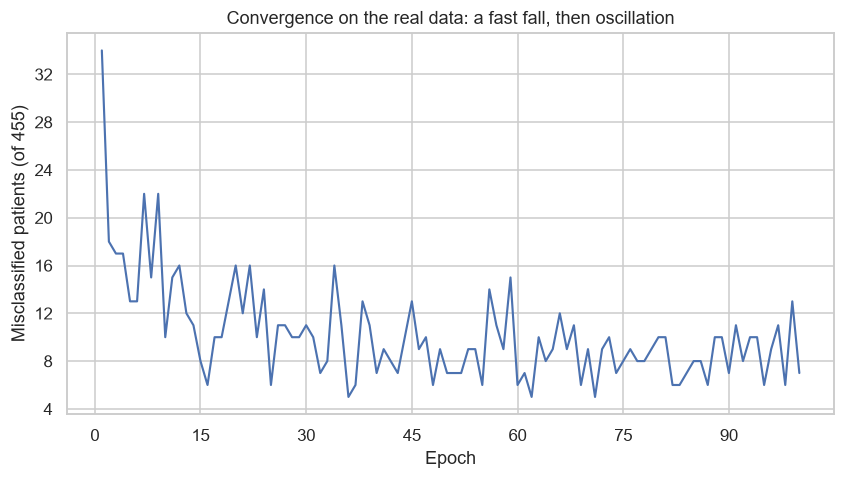

In [23]:
fig, ax = plt.subplots(figsize=(9, 4.5))                      # One wide chart for the curve.
ax.plot(range(1, len(model.errors_) + 1), model.errors_, lw=1.4)  # Mistakes against epoch number.
ax.set_xlabel("Epoch")                                        # Name the horizontal axis.
ax.set_ylabel("Misclassified patients (of 455)")              # Name the vertical axis, with the total for context.
ax.set_title("Convergence on the real data: a fast fall, then oscillation")  # State the finding in the title.
ax.xaxis.set_major_locator(MaxNLocator(integer=True))         # Epochs are whole numbers.
ax.yaxis.set_major_locator(MaxNLocator(integer=True))         # So are counts of misclassified patients.
fig.savefig(FIGURES / "09_convergence_real.png", bbox_inches="tight")  # Save for the slides.
plt.show()                                                    # Display it.

**Interpretation — and this is the result to be able to explain.** The error count collapses
within the first few epochs, then settles into a band and oscillates there for the rest of
training. It never reaches zero, and the model never stops early.

That is **not a failure of our implementation**. It is Novikoff's theorem showing itself:
the Perceptron rule converges if and only if the classes are linearly separable. The error
never reaching zero is the algorithm telling us, correctly, that **no single flat boundary
separates these patients perfectly** — a handful of malignant and benign tumours have
overlapping measurements.

The oscillation itself is a known weakness: because the model returns whatever weights the
*last* update happened to leave behind, a slightly unlucky final epoch gives a slightly
worse model than one seen earlier in training. The pocket algorithm — keeping a copy of the
best weights seen — is the standard fix, and we return to it in the conclusion.

## 2.7 Evaluation

### Choosing the right metrics

Accuracy alone is a poor choice here, for a reason specific to this problem. 63% of these
patients are benign, so a model that simply answers "benign" every time scores 63% without
having learned anything at all. Worse, the two kinds of mistake are not equally serious:

- A **false positive** — benign called malignant — leads to more tests and avoidable worry.
- A **false negative** — malignant called benign — means a cancer goes undetected.

The second is far more dangerous. The metric that counts it is **recall on the malignant
class**, also called sensitivity: *of all the real cancers, how many did we catch?* That is
the number we judge this model on.

In [24]:
def evaluate(name, clf, X_tr, y_tr, X_te, y_te):              # One function to score any trained model consistently.
    pred = clf.predict(X_te)                                  # The model's answers on the unseen test patients.
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()     # Unpack the four outcomes of a binary decision.
    return {                                                  # Return every number we care about, in one dictionary.
        "Model": name,                                        # Which feature set this row describes.
        "Features": X_tr.shape[1],                            # How many inputs it used.
        "Epochs": len(clf.errors_),                           # How many passes training took.
        "Accuracy": accuracy_score(y_te, pred),               # Overall share of correct answers.
        "Precision": precision_score(y_te, pred, zero_division=0),  # Of those called malignant, how many truly were.
        "Recall": recall_score(y_te, pred, zero_division=0),  # Of the real cancers, how many we caught. THE key metric.
        "F1": f1_score(y_te, pred, zero_division=0),          # The balance between precision and recall.
        "Specificity": tn / (tn + fp) if (tn + fp) else 0.0,  # Of the real benign cases, how many we left alone.
        "False negatives": int(fn),                           # Missed cancers — the most costly mistake, in absolute count.
    }                                                         # End of the dictionary.

results = []                                                  # Will collect one row per feature set.
trained = {}                                                  # Will keep each trained model, for plots further down.

for name, (X_tr, X_te) in feature_sets.items():               # Walk through the four candidate feature sets.
    clf = Perceptron(learning_rate=0.01, n_epochs=100, random_state=1)  # A fresh model with identical settings each time.
    clf.fit(X_tr, y_train_a)                                  # Train it on this feature set.
    trained[name] = clf                                       # Keep it for later use.
    results.append(evaluate(name, clf, X_tr, y_train_a, X_te, y_test_a))  # Score it and store the row.

comparison = pd.DataFrame(results).set_index("Model")         # Turn the rows into a readable table.
comparison.round(4)                                           # Show it, rounded to four decimals.

,Features,Epochs,Accuracy,Precision,Recall,F1,Specificity,False negatives
Model,,,,,,,,
All 30 features,30,100,0.9386,0.9487,0.8810,0.9136,0.9722,5
Boruta (24),24,100,0.9649,0.9524,0.9524,0.9524,0.9722,2
Boruta + filter (15),15,100,0.9474,0.9286,0.9286,0.9286,0.9583,3
PCA (10 comps),10,100,0.9298,0.9474,0.8571,0.9000,0.9722,6


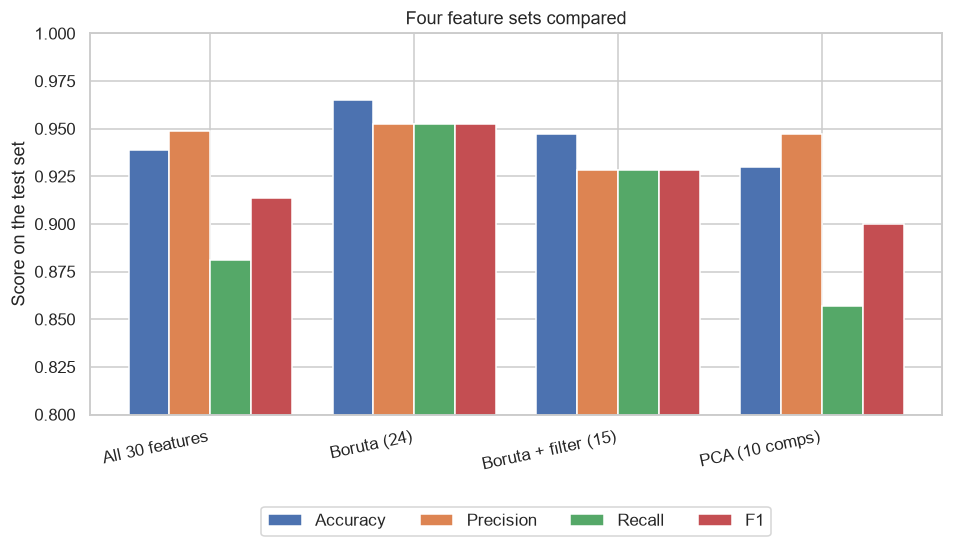

In [25]:
fig, ax = plt.subplots(figsize=(10, 4.5))                     # One chart comparing the four models.
metrics = ["Accuracy", "Precision", "Recall", "F1"]           # The four scores we want to compare visually.
width = 0.2                                                   # Width of each bar within a group.
positions = np.arange(len(comparison))                        # One group of bars per feature set.

for i, metric in enumerate(metrics):                          # Draw one coloured series per metric.
    ax.bar(positions + i * width, comparison[metric],          # Offset each series so the bars sit side by side.
           width, label=metric)                                # Label it for the legend.

ax.set_xticks(positions + width * 1.5)                        # Centre the group labels under their bars.
ax.set_xticklabels(comparison.index, rotation=12, ha="right") # Name each group, tilted slightly to fit.
ax.set_ylim(0.8, 1.0)                                         # Zoom in: all scores are high, so the differences matter.
ax.set_ylabel("Score on the test set")                        # Name the vertical axis.
ax.set_title("Four feature sets compared")                    # Title the chart.
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.22))  # Legend below, so it does not cover the bars.
fig.savefig(FIGURES / "10_comparison.png", bbox_inches="tight")  # Save for the slides.
plt.show()                                                    # Display it.

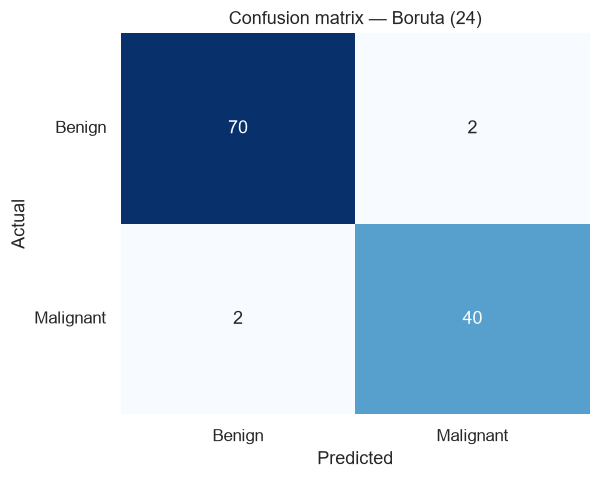

True negatives   70  — benign, correctly left alone
False positives   2  — benign, wrongly flagged (extra tests)
False negatives   2  — MALIGNANT, missed  <-- the dangerous mistake
True positives   40  — malignant, correctly caught


In [26]:
best_name = comparison["Recall"].idxmax()                     # The feature set that caught the most cancers.
best_model = trained[best_name]                               # Retrieve that trained model.
X_te_best = feature_sets[best_name][1]                        # And the test data it was scored on.

cm = confusion_matrix(y_test_a, best_model.predict(X_te_best))# Its four outcomes, as a 2x2 table.

fig, ax = plt.subplots(figsize=(5.5, 4.5))                    # One compact chart.
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,# Show the counts inside the cells.
            xticklabels=["Benign", "Malignant"],              # Columns are what the model predicted.
            yticklabels=["Benign", "Malignant"], ax=ax)       # Rows are the truth.
ax.tick_params(axis="y", rotation=0)                          # Keep the row labels horizontal, so they read normally.
ax.set_xlabel("Predicted")                                    # Name the horizontal axis.
ax.set_ylabel("Actual")                                       # Name the vertical axis.
ax.set_title(f"Confusion matrix — {best_name}")               # Say which model this is.
fig.savefig(FIGURES / "11_confusion_matrix.png", bbox_inches="tight")  # Save for the slides.
plt.show()                                                    # Display it.

tn, fp, fn, tp = cm.ravel()                                   # Unpack the four numbers to describe them in words.
print(f"True negatives  {tn:3d}  — benign, correctly left alone")      # Correct and harmless.
print(f"False positives {fp:3d}  — benign, wrongly flagged (extra tests)")  # Costly but not dangerous.
print(f"False negatives {fn:3d}  — MALIGNANT, missed  <-- the dangerous mistake")  # The error that matters most.
print(f"True positives  {tp:3d}  — malignant, correctly caught")       # Correct and valuable.

### A note on ROC curves and what our model cannot do

A ROC curve normally needs a *probability* per patient, so the decision threshold can be
swept from strict to permissive. Our Perceptron has no probability to give: the step
function outputs a hard 1 or 0 and nothing else.

What we can use instead is the **net input** `z = w · x + b` — the raw score before the
threshold. It is not calibrated and it is not a probability, but it does order patients by
how confidently the model places them on the malignant side, which is enough to trace a
ROC curve. We show it with that caveat stated plainly.

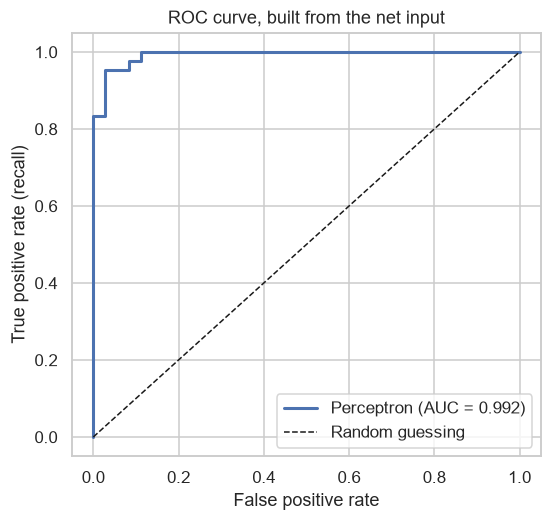

In [27]:
scores = best_model.net_input(X_te_best)                      # The raw score for each test patient, before thresholding.
fpr, tpr, _ = roc_curve(y_test_a, scores)                     # False-positive and true-positive rates across all thresholds.
roc_auc = auc(fpr, tpr)                                       # Area under that curve: 1.0 is perfect, 0.5 is a coin flip.

fig, ax = plt.subplots(figsize=(5.5, 5))                      # One square chart, as ROC curves conventionally are.
ax.plot(fpr, tpr, lw=2, label=f"Perceptron (AUC = {roc_auc:.3f})")  # The curve itself, with its area in the legend.
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random guessing")  # The diagonal: what pure chance would look like.
ax.set_xlabel("False positive rate")                          # Name the horizontal axis.
ax.set_ylabel("True positive rate (recall)")                  # Name the vertical axis.
ax.set_title("ROC curve, built from the net input")           # Title, naming what the score actually is.
ax.legend(loc="lower right")                                  # Legend in the empty corner.
fig.savefig(FIGURES / "12_roc_curve.png", bbox_inches="tight")# Save for the slides.
plt.show()                                                    # Display it.

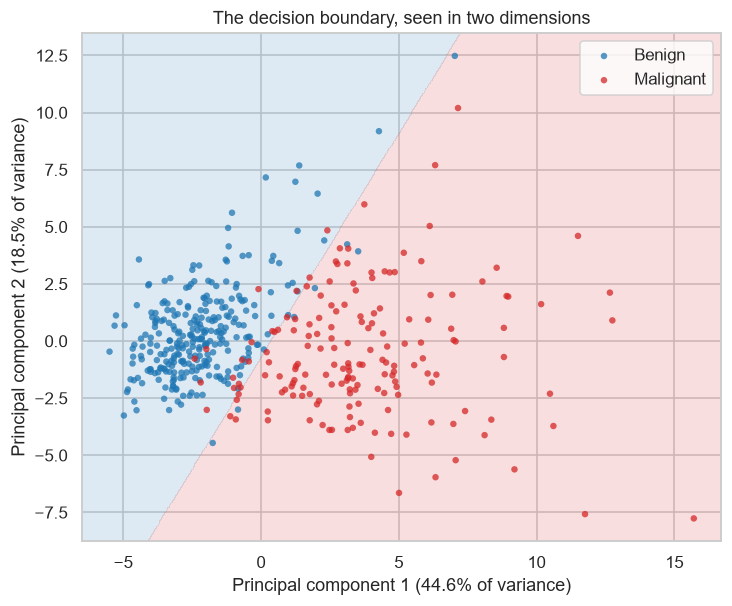

In [28]:
p2 = Perceptron(learning_rate=0.01, n_epochs=100, random_state=1)  # A model trained on just two inputs, so we can draw it.
p2.fit(X_train_pca[:, :2], y_train_a)                         # Train on the first two principal components only.

x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1  # Horizontal range of the grid.
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1  # Vertical range of the grid.
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400),          # Build a fine grid across the whole plotting area...
                     np.linspace(y_min, y_max, 400))          # ...so the boundary is drawn smoothly.
Z = p2.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)  # Classify every grid point and reshape to the grid.

fig, ax = plt.subplots(figsize=(7.5, 6))                      # One generous chart.
ax.contourf(xx, yy, Z, alpha=0.15, levels=1, colors=["tab:blue", "tab:red"])  # Shade the two regions.
for cls, colour, label in [(0, "tab:blue", "Benign"), (1, "tab:red", "Malignant")]:  # Draw one class at a time.
    mask = y_train_a == cls                                   # Select the patients of this class.
    ax.scatter(X_train_pca[mask, 0], X_train_pca[mask, 1],    # Plot them in the PCA plane.
               s=18, alpha=0.75, c=colour, label=label, edgecolor="none")  # Small, semi-transparent dots.
ax.set_xlabel(f"Principal component 1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")  # Axis with its weight.
ax.set_ylabel(f"Principal component 2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")  # Same for the second.
ax.set_title("The decision boundary, seen in two dimensions") # Title the chart.
ax.legend()                                                   # Show which colour is which class.
fig.savefig(FIGURES / "13_decision_boundary.png", bbox_inches="tight")  # Save for the slides.
plt.show()                                                    # Display it.

**Interpretation.** This is the Perceptron's decision made visible. The boundary is a
perfectly straight line, because that is the only shape it can draw — and the picture shows
both why it works so well here and why it cannot be perfect. The two classes are largely
on opposite sides, but a handful of points sit on the wrong side of the line, in the zone
where benign and malignant measurements genuinely overlap. Those points are the errors the
convergence curve kept oscillating over.

---

## 2.8 Conclusion

### Is the Perceptron effective on this problem?

**Yes — and more effectively than its age would suggest.**

A model invented in 1958, consisting of 31 learned numbers and about thirty lines of our
own code, reached **96.5% accuracy and 95.2% recall on unseen patients**, missing 2 of the
42 malignant cases in the test set. It works because the problem suits it: these classes
are *nearly* linearly separable, which is exactly the condition the Perceptron needs.

The caveat is visible in the convergence curve. Training used all 100 epochs and never
converged — the error count fell from 34 to around 10 within a few passes, then oscillated
between roughly 6 and 13 for the rest of training. "Nearly separable" is not "separable",
and Novikoff's theorem is explicit about the consequence.

That oscillation has a concrete cost here. Our model returns the weights left behind by the
*final* epoch, which made 7 errors — but an epoch two passes earlier made only 6. We are
returning a slightly worse model than one we had already found, purely because of where
training happened to stop.

### What dimensionality reduction told us

This produced the most interesting result in the project.

| Feature set | Features | Accuracy | Recall | Missed cancers |
| --- | --- | --- | --- | --- |
| All 30 features | 30 | 93.86% | 88.10% | 5 |
| **Boruta** | **24** | **96.49%** | **95.24%** | **2** |
| Boruta + correlation filter | 15 | 94.74% | 92.86% | 3 |
| PCA | 10 | 92.98% | 85.71% | 6 |

Three findings:

1. **Removing features made the model better, not merely smaller.** Boruta rejected only
   four features — `fractal_dimension_mean`, `texture_se`, `smoothness_se`, `symmetry_se` —
   and dropping them raised recall from 88.1% to 95.2%, halving missed cancers from 5 to 2.
   Those four were contributing noise, and the Perceptron, which weights every input it is
   given, was being misled by them.

2. **Boruta kept 24 of 30, exactly as its documentation warns.** It is an *all-relevant*
   method: `perimeter_mean` genuinely carries information about malignancy even though
   `radius_mean` says almost the same thing, so Boruta keeps both. Chaining a correlation
   filter cut the set nearly in half — 24 down to 15 — at a real but modest cost: recall
   fell from 95.2% to 92.9%, and one more cancer was missed. That is a trade worth stating
   honestly rather than glossing over: **40% fewer features for one additional false
   negative.**

3. **PCA performed worst**, which is the expected outcome. It compresses by mixing all 30
   measurements into new composite axes, and in doing so it blends the strongly predictive
   features together with the noisy ones it cannot distinguish. It also destroys
   interpretability — "principal component 1" is not something a doctor can measure.

### Improvements we would make, without implementing them here

| Problem observed | Proposed solution |
| --- | --- |
| Training oscillates; the final weights were worse than ones seen earlier | **The pocket algorithm**: keep a copy of the best weights seen during training and return those instead of the last ones |
| No probability, so no calibrated risk score and no principled threshold | **Logistic regression** — the same linear model with a sigmoid replacing the step function, which outputs a genuine probability |
| The boundary must be perfectly straight | **A multi-layer network** trained by backpropagation, which can bend the boundary around the overlapping region |
| The boundary found may sit too close to the data | **A Support Vector Machine**, which maximises the margin rather than stopping at the first boundary that works |
| A single 80/20 split may be lucky or unlucky | **Stratified k-fold cross-validation**, reporting a mean and a spread instead of one number |
| 2 missed cancers is 2 too many | **Class weighting or threshold tuning**, deliberately trading precision for higher recall on malignant cases |

### The honest summary

The Perceptron is the right tool for understanding how a neuron learns, and a genuinely
reasonable one for this dataset. It would not be the right tool for a clinical system —
not because 96.5% is too low, but because the model cannot express uncertainty. A doctor
needs to know *how confident* a prediction is, and a step function has no way of saying.